In [8]:
# notebooks/result_processing.ipynb

# ---
# # Experiment Results Analysis
# This notebook orchestrates the loading, analysis, and reporting of experiment
# results logged to Weights & Biases.
# ---

# ## 1. Setup and Imports
# Import necessary libraries and custom modules. The `sys.path.append` line
# allows the notebook to find the custom `lmetk_report` package.
import sys
import pandas as pd
sys.path.append('..')

from lmetk_report.run_processor import load_runs_df
from lmetk_report.analysis import analyze_results
from lmetk_report.reporting import create_summary_table

import seaborn as sns

%load_ext autoreload
%autoreload 2

# ---
# ## 2. Configuration
# Define all key parameters for the analysis in one place.
# ---



# PROJECT_NAME = "xjtu_sy_full"
# PROJECT_NAME = "nb14_full"
# PROJECT_NAME = "unibo_full"
PROJECT_NAME = "phme20_scaling"
PROJECT_NAME = "n_cmapss_scaling"
# PROJECT_NAME = "n_cmapss_final"
# PROJECT_NAME = "TabPFN_ds02_sweep_2025_10_09"
# PROJECT_NAME = "railway_traction_final"
# PROJECT_NAME = "phme20_full"
USER = "imos-buildingenergy-1"

METRIC_PREFIXES = [
    # "val/", 
    "test/"
]
REPORTING_METRICS = [
    # "loss", 
    "mse", 
    "mae", 
    "rmse",
    "mse_normalized",
    "mae_normalized",
    "rmse_normalized",
    "mse_denormalized",
    "mae_denormalized",
    "rmse_denormalized",
]


REPORTING_METRICS_BATTERY =  [f"{r}_mean" for r in REPORTING_METRICS] + ["phme_score_mean"]




# Configure pandas display options for better readability in the notebook.
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 200)

# ---
# ## 3. Data Loading
# Fetch data from wandb (or a local cache) and prepare the initial DataFrame.
# The `load_runs_df` function handles all the complex cleaning and flattening.
# ---
df, config_columns, dropped_columns = load_runs_df(
    project_name=PROJECT_NAME, 
    user=USER
)

# ---
# ## 4. Core Analysis
# Run the main analysis function to group results by dataset and model,
# find the best hyperparameter configuration, and collect performance metrics.
# ---

if "nb14" in PROJECT_NAME or "unibo" in PROJECT_NAME:


    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS_BATTERY,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_mean",
        optimization_mode="min"
    )
    
elif "n_cmapss" in PROJECT_NAME:
    
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_denormalized",
        optimization_mode="min"
    )
    
else:
    
    all_results = analyze_results(
        df=df,
        config_columns=config_columns,
        dropped_columns=dropped_columns,
        reporting_metrics=REPORTING_METRICS,
        metric_prefixes=METRIC_PREFIXES,
        optimization_col="test/mae_normalized",
        optimization_mode="min"
    )

# ---
# ## 5. Generate and Display Summary
# Create the final pivoted summary table for a high-level overview
# of the best performance for each model on each dataset.
# ---
summary_df = create_summary_table(all_results, precision=3)
summary_df.index = summary_df.index.str.split(".").str[-1].str.replace("_", "-")  # Simplify model names

print("\n📊 Final Performance Summary Table:")
display(summary_df)



The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
Fetching runs from wandb project: imos-buildingenergy-1/n_cmapss_scaling...


 74%|███████▍  | 752/1018 [04:53<08:00,  1.81s/it]

Skipping run '0.1+concepts_n_cmapss+prognostics+tabdpt_fit_predict_411bb307' with state 'crashed'


 74%|███████▍  | 754/1018 [04:53<04:30,  1.03s/it]

Skipping run '0.1+concepts_n_cmapss_ds02+prognostics+tabdpt_fit_predict_d1b138b0' with state 'crashed'


...

 80%|████████  | 819/1018 [05:16<00:54,  3.65it/s]

Skipping run '0.2+concepts_n_cmapss+prognostics+tabdpt_fit_predict_1d86b8d9' with state 'crashed'


100%|██████████| 1018/1018 [06:28<00:00,  2.62it/s]


Skipping run '0.005+concepts_n_cmapss+prognostics+tabpfn_fit_predict_5f5374ee' with state 'running'
Saved 1013 runs to cache: csv_files/n_cmapss_scaling.csv
Dropped 71 columns with >90% NaN values.
The columns were drropped: ['ckpt_path', 'profiler_cfg', 'subset_range', 'val_subset_ratio', 'test_subset_ratio', 'd_x_mask', 'optimizer_factory', 'scheduler_factory', 'freq', 'pad_value', 'null_value', 'target_mask', 'variable_emb_type', 'datasource.val1.units', 'datasource.val1.data_splitter', 'datasource.test1.units', 'datasource.test1.data_splitter', 'datasource.train1.units', 'datasource.train1.data_splitter', 'datasource.source_list.val1.units', 'datasource.source_list.val1.data_splitter', 'datasource.source_list.test1.units', 'datasource.source_list.test1.data_splitter', 'datasource.source_list.train1.units', 'datasource.source_list.train1.data_splitter', 'datasource.val2.units', 'datasource.val2.data_splitter', 'datasource.val3.units', 'datasource.val3.data_splitter', 'datasource.val

Dataset                           MultiSource_concepts_N-CMAPSS                                                                                                                            \
Metric                                                 test/mae test/mae_denormalized  test/mae_normalized         test/mse   test/mse_denormalized  test/mse_normalized        test/rmse   
Model                                                                                                                                                                                       
Crossformer-Forecaster                          nan ± nan (n=0)  15.495 ± 1.558 (n=5)  0.155 ± 0.016 (n=5)  nan ± nan (n=0)  378.035 ± 61.704 (n=5)  0.038 ± 0.006 (n=5)  nan ± nan (n=0)   
LSTM-Forecaster                                 nan ± nan (n=0)  11.942 ± 0.882 (n=5)  0.119 ± 0.009 (n=5)  nan ± nan (n=0)  230.494 ± 35.040 (n=5)  0.023 ± 0.004 (n=5)  nan ± nan (n=0)   
PatchTST-Forecaster                             nan ± nan (n=0)  21.533 ± 0.008 (n=5)  0.215 ± 0.000 (n=5)  nan ± nan (n=0)   633.241 ± 0.749 (n=5)  0.063 ± 0.000 (n=5)  nan ± nan (n=0)   
Spacetimeformer-Forecaster                      nan ± nan (n=0)  11.391 ± 0.928 (n=5)  0.114 ± 0.009 (n=5)  nan ± nan (n=0)  216.299 ± 35.437 (n=5)  0.022 ± 0.004 (n=5)  nan ± nan (n=0)   
TiDE-Forecaster                                 nan ± nan (n=0)  41.795 ± 0.028 (n=5)  0.418 ± 0.000 (n=5)  nan ± nan (n=0)  2369.487 ± 2.386 (n=5)  0.237 ± 0.000 (n=5)  nan ± nan (n=0)   
Timeseries-Transformer-Forecaster               nan ± nan (n=0)  11.101 ± 0.196 (n=5)  0.111 ± 0.002 (n=5)  nan ± nan (n=0)   203.070 ± 5.613 (n=5)  0.020 ± 0.001 (n=5)  nan ± nan (n=0)   
FitPredictTabDPTWrapper                         nan ± nan (n=0)     7.105 ± nan (n=1)    0.071 ± nan (n=1)  nan ± nan (n=0)      96.639 ± nan (n=1)    0.010 ± nan (n=1)  nan ± nan (n=0)   
FitPredictTabPFNWrapper                         nan ± nan (n=0)     7.785 ± nan (n=1)    0.078 ± nan (n=1)  nan ± nan (n=0)     114.979 ± nan (n=1)    0.011 ± nan (n=1)  nan ± nan (n=0)   

Dataset                                                                        
Metric                            test/rmse_denormalized test/rmse_normalized  
Model                                                                          
Crossformer-Forecaster              19.394 ± 1.544 (n=5)  0.194 ± 0.015 (n=5)  
LSTM-Forecaster                     15.148 ± 1.130 (n=5)  0.151 ± 0.011 (n=5)  
PatchTST-Forecaster                 25.164 ± 0.015 (n=5)  0.252 ± 0.000 (n=5)  
Spacetimeformer-Forecaster          14.670 ± 1.167 (n=5)  0.147 ± 0.012 (n=5)  
TiDE-Forecaster                     48.677 ± 0.025 (n=5)  0.487 ± 0.000 (n=5)  
Timeseries-Transformer-Forecaster   14.249 ± 0.195 (n=5)  0.142 ± 0.002 (n=5)  
FitPredictTabDPTWrapper                9.831 ± nan (n=1)    0.098 ± nan (n=1)  
FitPredictTabPFNWrapper               10.723 ± nan (n=1)    0.107 ± nan (n=1)

In [15]:
print(summary_df.to_latex())

\begin{tabular}{lllllll}
\toprule
Dataset & \multicolumn{6}{r}{MultiSource_concepts_N-CMAPSS} \\
Metric & test/mae & test/mae_normalized & test/mse & test/mse_normalized & test/rmse & test/rmse_normalized \\
Model &  &  &  &  &  &  \\
\midrule
Crossformer-Forecaster & nan ± nan (n=0) & 0.155 ± 0.016 (n=5) & nan ± nan (n=0) & 0.038 ± 0.006 (n=5) & nan ± nan (n=0) & 0.194 ± 0.015 (n=5) \\
LSTM-Forecaster & nan ± nan (n=0) & 0.119 ± 0.009 (n=5) & nan ± nan (n=0) & 0.023 ± 0.004 (n=5) & nan ± nan (n=0) & 0.151 ± 0.011 (n=5) \\
PatchTST-Forecaster & nan ± nan (n=0) & 0.215 ± 0.000 (n=5) & nan ± nan (n=0) & 0.063 ± 0.000 (n=5) & nan ± nan (n=0) & 0.252 ± 0.000 (n=5) \\
Spacetimeformer-Forecaster & nan ± nan (n=0) & 0.114 ± 0.009 (n=5) & nan ± nan (n=0) & 0.022 ± 0.004 (n=5) & nan ± nan (n=0) & 0.147 ± 0.012 (n=5) \\
TiDE-Forecaster & nan ± nan (n=0) & 0.418 ± 0.000 (n=5) & nan ± nan (n=0) & 0.237 ± 0.000 (n=5) & nan ± nan (n=0) & 0.487 ± 0.000 (n=5) \\
Timeseries-Transformer-Forecaster & nan

For N-CMAPSS:

In [9]:
conflicts = df["test/mae"].notna() & df["test/mae_normalized"].notna()
print(conflicts.any(), df[conflicts].shape[0])

df["test/mae_normalized"] = df["test/mae_normalized"].combine_first(df["test/mae"])
df["test/rmse_normalized"] = df["test/rmse_normalized"].combine_first(df["test/rmse"])
df["test/mae_denormalized"] = df["test/mae_denormalized"].combine_first(df["test/mae"])
df["test/rmse_denormalized"] = df["test/rmse_denormalized"].combine_first(df["test/rmse"])

False 0


For NCMAPSS:

In [10]:

df_long = df[[
    "test/mae_normalized", 
    "test/rmse_normalized",
    "test/mae_denormalized", 
    "test/rmse_denormalized", 
    "model._target_", 
    "seed", 
    "task_definition.subset_ratio", 
    "task_definition.seq_len"]]
df_long
df_long["ds"] = df["datasource.multisource_data_splitter.sources_train"].astype(str) 

df_long = df_long.melt(
    id_vars=[
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
        "ds"
    ],
    value_vars=["test/mae_normalized", "test/rmse_normalized", "test/mae_denormalized", "test/rmse_denormalized"],
    var_name="metric",
    value_name="value"
)
df_long


df_long = df_long[~((df_long["model._target_"] == "lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper") & (df_long["task_definition.seq_len"] == 5))]
df_long.head()



/var/folders/8w/nzvg2wnj1vg1xcs7s2d8097j3kqzdw/T/ipykernel_67645/3135675653.py:11: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_long["ds"] = df["datasource.multisource_data_splitter.sources_train"].astype(str)


,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,ds,metric,value
0,lmetk.model.wrappers.fit_predict_tabdpt_wrappe...,72,0.1,1,['train1'],test/mae_normalized,5.577186
1,lmetk.baselines.crossformer_model.Crossformer_...,72,0.1,50,['train1'],test/mae_normalized,7.295566
2,lmetk.baselines.crossformer_model.Crossformer_...,88,0.1,50,['train1'],test/mae_normalized,8.563116
3,lmetk.baselines.crossformer_model.Crossformer_...,101,0.1,50,['train1'],test/mae_normalized,8.502600
4,lmetk.baselines.crossformer_model.Crossformer_...,666,0.1,50,['train1'],test/mae_normalized,7.182355


In [4]:

df_long = df[[
    "test/mae_normalized", 
    "test/rmse_normalized",
    "model._target_", 
    "seed", 
    "task_definition.subset_ratio", 
    "task_definition.seq_len"]]

df_long = df_long.melt(
    id_vars=[
        "model._target_",
        "seed",
        "task_definition.subset_ratio",
        "task_definition.seq_len",
    ],
    value_vars=["test/mae_normalized", "test/rmse_normalized"],
    var_name="metric",
    value_name="value"
)
df_long


df_long = df_long[~((df_long["model._target_"] == "lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper") & (df_long["task_definition.seq_len"] == 5))]
df_long.head()


,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value
0,lmetk.baselines.crossformer_model.Crossformer_...,72,0.001,16,test/mae_normalized,0.176467
1,lmetk.baselines.crossformer_model.Crossformer_...,88,0.001,16,test/mae_normalized,0.175738
2,lmetk.baselines.crossformer_model.Crossformer_...,101,0.001,16,test/mae_normalized,0.178742
3,lmetk.baselines.crossformer_model.Crossformer_...,666,0.001,16,test/mae_normalized,0.175825
4,lmetk.baselines.crossformer_model.Crossformer_...,226688,0.001,16,test/mae_normalized,0.179956


/var/folders/8w/nzvg2wnj1vg1xcs7s2d8097j3kqzdw/T/ipykernel_67645/170186164.py:49: UserWarning: Attempt to set non-positive xlim on a log-scaled axis will be ignored.
  ax.set_xlim(0.0, 1.0)


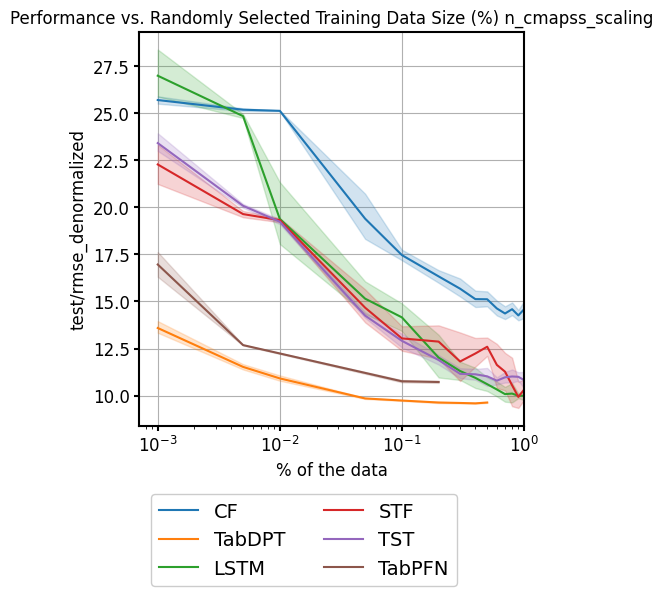

In [11]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,5))    

if "n_cmapss" in PROJECT_NAME:
    plot_df = df_long[df_long["ds"] == df_long["ds"].unique()[1]]
    metric = "test/rmse_denormalized"
elif "phme20" in PROJECT_NAME:
    plot_df = df_long
    metric = "test/mae_normalized"
else:
    raise ValueError("Unknown project for plotting")

plot_df.to_csv("scaling_laws_railway_mape.csv", index=False)

def extract_handles_labels_title(ax):
    old_legend = ax.legend_
    handles = old_legend.legend_handles
    labels = [t.get_text() for t in old_legend.get_texts()]
    title = old_legend.get_title().get_text()
    old_legend.remove()
    return handles, labels, title
    # ax.legend(handles, labels, loc=new_loc, title=title, **kws)


# dashes = {m: (2, 2) if m in ["cf-plan", "stf-plan", "tf-plan", "tide-plan"] else "" for m in ccdfs.variable.unique()}


sns.lineplot(plot_df[plot_df["model._target_"].isin(
            [
                "lmetk.baselines.lstm_model.LSTM_Forecaster",
                 'lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper',
                 'lmetk.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper',
                 'lmetk.baselines.spacetimeformer_model.Spacetimeformer_Forecaster',
                 'lmetk.baselines.crossformer_model.Crossformer_Forecaster',
                 'lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster'
            ]) & (plot_df["metric"] == metric)],
             x="task_definition.subset_ratio", y="value", hue="model._target_", 
            #  palette=palette, ax=ax, dashes=dashes, style="variable", alpha=1
             )
# ax.set_yscale('log')

ax.set_title(f"Performance vs. Randomly Selected Training Data Size (%) {PROJECT_NAME}")
ax.set_ylabel(metric, size=12)
ax.set_xlabel("% of the data", size=12)
# ax.set_yscale('log')
ax.set_xscale('log')
ax.set_axisbelow(True)
ax.set_xlim(0.0, 1.0)
ax.grid()


# Add a box around the plot
for spine in ax.spines.values():
    spine.set_visible(True)  # Make all spines visible
    spine.set_linewidth(1.5)  # Adjust the box line width if needed
    spine.set_color('black')      # Set the color of the frame

# Set tick indicators (tick marks) thickness to 1.5
ax.tick_params(axis='x', width=1.5, labelsize=12)  # X-axis tick indicators
ax.tick_params(axis='y', width=1.5, labelsize=12)  # Y-axis tick indicators

variable_rename = {
       'lmetk.baselines.crossformer_model.Crossformer_Forecaster': "CF",
       'lmetk.baselines.lstm_model.LSTM_Forecaster': "LSTM",
       'lmetk.baselines.patchtst_model.PatchTST_Forecaster': "PatchTST",
       'lmetk.baselines.spacetimeformer_model.Spacetimeformer_Forecaster': "STF",
       'lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper': "TabDPT",
       'lmetk.model.wrappers.fit_predict_tabpfn_wrapper.FitPredictTabPFNWrapper': "TabPFN",
       'lmetk.baselines.tide_model.TiDE_Forecaster': "TiDE",
       'lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster': "TST",
}

handles, labels, title = extract_handles_labels_title(ax)   
labels = [variable_rename[l] for l in labels]

legend = fig.legend(
handles=handles, 
labels=labels, 
title='', 
loc='upper center', 
bbox_to_anchor=(0.5, 0.02), 
ncol=2, 
framealpha=1, fontsize=14
)

fig.tight_layout()
fig.savefig(f'lmetk_report_artifacts/scaling_laws_ncmapss_{metric.split("/")[1]}.pdf', 
            dpi=300, transparent=True, bbox_extra_artists=(legend,), bbox_inches='tight')

In [9]:
plot_df[plot_df["model._target_"] == "lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabPFNWrapper"]

,model._target_,seed,task_definition.subset_ratio,task_definition.seq_len,metric,value


In [3]:
for key in all_results.keys():
    print(f"Dataset key: {key}")
    for key_2 in all_results[key].keys():
        print(f"  Model key: {key_2}")
        for sub_key in all_results[key][key_2].keys():
            #if pd data frame then display the head only
            if isinstance(all_results[key][key_2][sub_key], pd.DataFrame):
                print(f"    {sub_key}:")
                display(all_results[key][key_2][sub_key].head(2))
            # if dict proceed with keys 
            elif isinstance(all_results[key][key_2][sub_key], dict):
                # same for inside dict and repeat
                for inner_key in all_results[key][key_2][sub_key].keys():
                    # print the 
                    if isinstance(all_results[key][key_2][sub_key][inner_key], pd.DataFrame):
                        print(f"   {sub_key}   {inner_key}:")
                        display(all_results[key][key_2][sub_key][inner_key].head(2))
                    else:
                        print(f" {sub_key}     {inner_key}: {all_results[key][key_2][sub_key][inner_key]}")
                
            else:
                print(f"    {sub_key}: {all_results[key][key_2][sub_key]}")
            
            


Dataset key: MultiSource_concepts_N-CMAPSS
  Model key: lmetk.model.wrappers.fit_predict_tabdpt_wrapper.FitPredictTabDPTWrapper
 best_hyperparameters     datasource.val1.window_size: 5
 best_hyperparameters     datasource.val2.window_size: 5
 best_hyperparameters     datasource.val3.window_size: 5
 best_hyperparameters     datasource.val4.window_size: 5
 best_hyperparameters     datasource.test1.window_size: 5
 best_hyperparameters     datasource.test2.window_size: 5
 best_hyperparameters     datasource.test3.window_size: 5
 best_hyperparameters     datasource.test4.window_size: 5
 best_hyperparameters     datasource.train1.window_size: 5
 best_hyperparameters     datasource.train2.window_size: 5
 best_hyperparameters     datasource.train3.window_size: 5
 best_hyperparameters     datasource.train4.window_size: 5
 best_hyperparameters     datasource.source_list.val1.window_size: 5
 best_hyperparameters     datasource.source_list.val2.window_size: 5
 best_hyperparameters     datasource.s

Model datasource.val1.window_size datasource.val2.window_size datasource.val3.window_size datasource.val4.window_size datasource.test1.window_size  \
                                                                                                                                                                                                    
2  lmetk.model.wrappers.fit_predict_tabdpt_wrappe...                           5                           5                           5                           5                            5   
3  lmetk.model.wrappers.fit_predict_tabdpt_wrappe...                           5                           5                           5                           5                            5   

  datasource.test2.window_size datasource.test3.window_size datasource.test4.window_size datasource.train1.window_size datasource.train2.window_size datasource.train3.window_size  \
                                                                                                                                                                                     
2                            5                            5                            5                             5                             5                             5   
3                            5                            5                            5                             5                             5                             5   

  datasource.train4.window_size datasource.source_list.val1.window_size datasource.source_list.val2.window_size datasource.source_list.val3.window_size datasource.source_list.val4.window_size  \
                                                                                                                                                                                                  
2                             5                                       5                                       5                                       5                                       5   
3                             5                                       5                                       5                                       5                                       5   

  datasource.source_list.test1.window_size datasource.source_list.test2.window_size datasource.source_list.test3.window_size datasource.source_list.test4.window_size  \
                                                                                                                                                                        
2                                        5                                        5                                        5                                        5   
3                                        5                                        5                                        5                                        5   

  datasource.source_list.train1.window_size datasource.source_list.train2.window_size datasource.source_list.train3.window_size datasource.source_list.train4.window_size task_definition.seq_len  \
                                                                                                                                                                                                    
2                                         5                                         5                                         5                                         5                       5   
3                                         5                                         5                                         5                                         5                       5   

  task_definition.stride_train val/loss           val/mse           val/mae           val/rmse           test/loss              test/mse            test/mae            test/rmse            \
                                   mean std count    mean std count    mean std count     m

    non_aggregated_df:


,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

  Model key: lmetk.model.wrappers.cnn1d_wrapper.CNN1D_Wrapper
 best_hyperparameters     datamodule.train_batch_size: 512
 best_hyperparameters     run_names: ['concepts_n_cmapss+prognostics+cnn_1d_d699bee0', 'concepts_n_cmapss+prognostics+cnn_1d_4f740e7c', 'concepts_n_cmapss+prognostics+cnn_1d_9e6fea91', 'concepts_n_cmapss+prognostics+cnn_1d_e5fdcc2d', 'concepts_n_cmapss+prognostics+cnn_1d_515c214c']
 best_performance     optimized_on: {'metric': 'val/loss', 'strategy': 'min'}
 best_performance     metrics: defaultdict(<class 'dict'>, {'loss': {'val': {'mean': np.float64(0.011044347286224365), 'std': np.float64(0.0017331504046561536), 'count': np.int64(5)}, 'test': {'mean': np.float64(0.012568620406091214), 'std': np.float64(0.000950910528531216), 'count': np.int64(5)}}, 'mse': {'val': {'mean': np.float64(110.4434814453125), 'std': np.float64(17.331517778541826), 'count': np.int64(5)}, 'test': {'mean': np.float64(125.68621063232422), 'std': np.float64(9.509102911881142), 'count': np.in

...

,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

  Model key: lmetk.baselines.timeseries_transformer_model.Timeseries_Transformer_Forecaster
 best_hyperparameters     datamodule.train_batch_size: 16
 best_hyperparameters     run_names: ['concepts_n_cmapss+prognostics+timeseries_transformer_25c702f8', 'concepts_n_cmapss+prognostics+timeseries_transformer_429a576d', 'concepts_n_cmapss+prognostics+timeseries_transformer_f52d1d3f', 'concepts_n_cmapss+prognostics+timeseries_transformer_ccee915b', 'concepts_n_cmapss+prognostics+timeseries_transformer_4438bc1c']
 best_performance     optimized_on: {'metric': 'val/loss', 'strategy': 'min'}
 best_performance     metrics: defaultdict(<class 'dict'>, {'loss': {'val': {'mean': np.float64(0.056804065406322476), 'std': np.float64(0.0002748226997781393), 'count': np.int64(5)}, 'test': {'mean': np.float64(0.06315606236457824), 'std': np.float64(0.0007212215500439141), 'count': np.int64(5)}}, 'mse': {'val': {'mean': np.float64(568.0407104492188), 'std': np.float64(2.748128322120955), 'count': np.int6

Model datamodule.train_batch_size  val/loss                     val/mse                    val/mae                   val/rmse                  \
                                                                                      mean       std count        mean       std count       mean       std count       mean       std count   
0  lmetk.baselines.timeseries_transformer_model.T...                          16  0.056804  0.000275     5  568.040710  2.748128     5  20.423397  0.044695     5  23.833549  0.057665     5   
1  lmetk.baselines.timeseries_transformer_model.T...                         512  0.057125  0.000772     5  571.250952  7.715422     5  20.470219  0.120922     5  23.900421  0.161321     5   

  test/loss                    test/mse                   test/mae                  test/rmse                                                           run_name  
       mean       std count        mean       std count       mean       std count       mean       std count                                               list  
0  0.063156  0.000721     5  631.560522  7.211879     5  21.518312  0.077898     5  25.130542  0.143050     5  [concepts_n_cmapss+prognostics+timeseries_tran...  
1  0.063162  0.000219     5  631.615808  2.193418     5  21.516906  0.023078     5  25.131938  0.043647     5  [concepts_n_cmapss+prognostics+timeseries_tran...

    non_aggregated_df:


,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,test/loss,test/mae,test/mse,test/nasa_score,test/rmse,test_best_rerun/loss,test_best_rerun/mae,test_best_rerun/mse,test_best_rerun/nasa_score,test_best_rerun/rmse,train/loss_epoch,train/loss_step,train/mae,train/mse,train/nasa_score,train/rmse,trainer/global_step,val/loss,val/mae,val/mse,val/nasa_score,val/rmse,val_best_rerun/loss,val_best_rerun/mae,val_best_rerun/mse,val_best_rerun/nasa_score,val_best_rerun/rmse,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_threads,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,flash_attention,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,enable_progress_bar,model/params/trainable,run_name,d_x,d_ff,d_yc,d_yt,ts_in,device,factor,ts_out,base_lr,d_model,dropout,init_lr,n_heads,seg_len,verbose,baseline,e_layers,l2_coeff,mask_y_c,metadata,patience,win_size,task_type,use_revin,evaluators,decay_factor,warmup_steps,learning_rate,linear_window,decoder_embedding,use_seasonal_decomp,linear_shared_weights,scheduler_Loss_monitor,n_layers,dropout_p,hidden_dim,time_emb_dim,teacher_forcing_prob,lr-AdamW,d_layers,use_x_dim,include_x_t,transformer_args,norm,head_f,d_values,use_time,use_given,use_space,activation,dropout_ff,use_tt_dec,use_tt_enc,attn_factor,dropout_emb,dropout_qkv,max_seq_len,use_val_dec,use_val_enc,embed_method,pos_emb_type,time_emb_type,class_loss_imp,d_queries_keys,n_timefeatures,performer_relu,recon_loss_imp,use_final_norm,local_self_attn,start_token_len,attention_method,dropout_attn_out,global_self_attn,inverted_encoder,local_cross_attn,performer_kernel,attn_time_windows,global_cross_attn,timetable_emb_type,dropout_attn_matrix,recon_mask_drop_seq,recon_mask_skip_all,recon_mask_drop_full,recon_mask_max_seq_len,initial_downsample_convs,recon_mask_drop_standard,use_shifted_time_windows,performer_redraw_interval,intermediate_downsample_convs,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_name,datasource.task_mode,datasource._recursive_,datasource.val1.RUL,datasource.val1.mode,datasource.val1.n_DS,datasource.val1.path,datasource.val1.cruise,datasource.val1.stride,datasource.val1.scaling,datasource.val1._target_,datasource.val1.concepts,datasource.val1.data_name,datasource.val1.task_mode,datasource.val1.data_folder,datasource.val1.window_size,datasource.val1.group_by_unit,datasource.val1.load_arguments.mode,datasource.val1.load_arguments.n_DS,datasource.val1.load_arguments.units,datasource.val1.binary_concepts,datasource.val1.include_healthy,datasource.val1.subsampling_rate,datasource.val1.combined_concepts,datasource.val2.RUL,datasource.val2.mode,datasource.val2.n_DS,datasource.val2.path,datasource.val2.cruise,datasource.val2.stride,datasource.val2.scaling,datasource.val2._target_,datasource.val2.concepts,datasource.val2.data_name,datasource.val2.task_mode,datasource.val2.data_folder,datasource.val2.window_size,datasource.val2.group_by_unit,datasource.val2.load_arguments.mode,datasource.val2.load_arguments.n_DS,datasource.val2.load_arguments.units,datasource.val2.binary_concepts,datasource.val2.include_healthy,datasource.val2.subsampling_rate,datasource.val2.combined_concepts,datasource.val3.RUL,datasource.val3.mode,datasource.val3.n_DS,datasource.val3.path,datasource.val3.cruise,datasource.val3.stride,datasource.val3.scaling,datasource.val3._target_,datasource.val3.concepts,datasource.val3.data_name,datasource.val3.task_mode,datasource.val3.data_folder,datasource.val3.window_size,datasource.val3.group_by_unit,datasource.val3

In [4]:
display(all_results[key][key_2]['sorted_aggregated_results'])

Model                    model.kernels                   model.strides                 model.dilations                     model.output_channels  \
                                                                                                                                                                                                  
0  lmetk.model.autoencoder.wrapper.AutoencoderWra...                  (5, 5, 5, 5, 5)                 (1, 1, 1, 1, 1)                 (1, 2, 4, 8, 1)                      (16, 32, 64, 64, 64)   
2  lmetk.model.autoencoder.wrapper.AutoencoderWra...  (10, 7, 7, 7, 7, 7, 7, 7, 7, 7)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (1, 1, 1, 1, 1, 1, 1, 1, 1, 1)  (16, 32, 64, 64, 64, 16, 32, 64, 64, 64)   
1  lmetk.model.autoencoder.wrapper.AutoencoderWra...                  (7, 7, 5, 5, 5)                 (2, 2, 1, 1, 1)                 (1, 1, 1, 1, 1)                      (16, 32, 64, 64, 64)   

   val/loss       val/mse       val/mae      val/rmse     test/loss      test/mse      test/mae     test/rmse                                               run_name  
       mean std      mean std      mean std      mean std      mean std      mean std      mean std      mean std                                               list  
0  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  0.000058 NaN  0.000058 NaN  0.004978 NaN  0.007645 NaN  [pronostia+reconstruction+residual_autoencoder...  
2  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  0.000063 NaN  0.000063 NaN  0.005087 NaN  0.007926 NaN  [pronostia+reconstruction+residual_autoencoder...  
1  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  0.000082 NaN  0.000082 NaN  0.005265 NaN  0.009032 NaN  [pronostia+reconstruction+residual_autoencoder...

In [ ]:
for i in all_results[key][key_2]['non_aggregated_df']['callbacks.model_checkpoint.dirpath']:
    print(str(i))
    

/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-38/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_03-30-47/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_11-49-26/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_12-25-24/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_20-06-41/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-02_21-16-34/checkpoints/checkpoints
/home/levtel/projects/TabPHM/artifacts/debug/runs/pronostia+reconstruction+residual_autoencoder/2025-10-03_04-29-43/checkpoints/checkpoints
/home/levtel/project

In [45]:
all_results[key][key_2]['non_aggregated_df']

,_runtime,_step,_timestamp,_wandb,epoch,lr-Adam,train/loss_step,trainer/global_step,loss,seed,tags,test,cache,train,logger,trainer,exp_name,evaluator,hydra_cfg,pin_memory,transforms,num_workers,shuffle_val,shuffle_test,shuffle_train,val_batch_size,prefetch_factor,test_batch_size,experiment_group,train_batch_size,use_batch_sampler,model/params/total,model/params/trainable,run_name,AvgTime/train_batch_mean,AvgTime/train_batch_std,AvgTime/train_epoch_mean,AvgTime/train_epoch_std,AvgTime/val_batch_mean,AvgTime/val_batch_std,AvgTime/val_epoch_mean,AvgTime/val_epoch_std,plots/test/reconstructions_overview,plots/train/reconstructions_overview,plots/val/reconstructions_overview,test/loss,test/mae,test/mse,test/rmse,train/loss_epoch,train/mae,train/mse,train/rmse,val/loss,val/mae,val/mse,val/rmse,num_threads,optimizer._target_,optimizer.optimizer_id,optimizer.scheduler.scheduler_id,optimizer.scheduler.scheduler_params.gamma,optimizer.scheduler.scheduler_params.step_size,optimizer.parameters.lr,optimizer.parameters.weight_decay,datasource._target_,datasource.data_dir,datasource.data_name,datasource.task_mode,datasource.fold,datasource.cache_dir,task_definition.stride,task_definition.seq_len,task_definition.pred_len,task_definition.label_len,task_definition.task_type,task_definition.requires_training,task_definition.model.data_requirements.input_tensors,model.kernels,model.strides,model._target_,model.dilations,model.latent_dim,model.dropout_prob,model.input_seq_len,model.input_channels,model.output_channels,model.blocks_config,dataset._target_,dataset._recursive_,dataset.dataset_cfg.stride,dataset.dataset_cfg.seq_len,dataset.dataset_cfg._target_,dataset.dataset_cfg.pred_len,dataset.dataset_cfg.label_len,datamodule._target_,datamodule.num_workers,datamodule.shuffle_val,datamodule.shuffle_test,datamodule.shuffle_train,datamodule.val_batch_size,datamodule.prefetch_factor,datamodule.test_batch_size,datamodule.train_batch_size,callbacks.model_timer._target_,callbacks.model_summary._target_,callbacks.model_summary.max_depth,callbacks.early_stopping.mode,callbacks.early_stopping.strict,callbacks.early_stopping.monitor,callbacks.early_stopping.verbose,callbacks.early_stopping._target_,callbacks.early_stopping.patience,callbacks.early_stopping.min_delta,callbacks.early_stopping.check_finite,callbacks.model_checkpoint.mode,callbacks.model_checkpoint.dirpath,callbacks.model_checkpoint.monitor,callbacks.model_checkpoint.verbose,callbacks.model_checkpoint._target_,callbacks.model_checkpoint.filename,callbacks.model_checkpoint.save_last,callbacks.model_checkpoint.save_top_k,callbacks.model_checkpoint.save_weights_only,callbacks.model_checkpoint.auto_insert_metric_name,callbacks.learning_rate_monitor._target_,callbacks.learning_rate_monitor.logging_interval,Model
52,29813,31573,1.759431e+09,{'runtime': 29813},20,0.00500,6.167217e-05,1573580,{'_target_': 'lmetk.loss.default.MSELoss'},42,[dev],True,"{'use_cache_after_loading': True, 'use_cache_a...",True,{'wandb': {'id': 'pronostia+reconstruction+res...,"{'devices': [1], '_target_': 'lightning.pytorc...",pronostia/reconstruction/residual_autoencoder,{'val': {'paths': {'log_dir': '/home/levtel/pr...,"{'job': {'id': '???', 'num': '???', 'name': '$...",True,{'scaler_features': {'metadata': {'fit_on': 't...,4,False,False,True,1024,10,1024,debug,128,True,183208,183208,pronostia+reconstruction+residual_autoencoder_...,0.015844,0.003353,1487.310064,21.117129,0.006290,0.001688,67.621402,2.877372,"{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...","{'_type': 'plotly-file', 'path': 'media/plotly...",1.429764e-04,0.007379,2.859528e-04,0.011957,6.198527e-02,0.012541,1.239705e-01,2.489684e-01,1.429764e-04,0.007379,2.859528e-04,0.011957,NaN,lmetk.optimizer.default.DefaultOptimizer,Adam,StepLR,0.5,10,0.0100,0,lmetk.data.datasources.phmd_pronostia.Pronosti...,NaN,PRONOSTIA,rul,0.0,/home/levtel/projects/TabPHM/datasets/phmd_cache,1,64,0,0,reconstruction,True,[features]

In [36]:
# If run_name is the first element in the tuple
